<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/susy_field_theory/susyft_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Field Theory* — `susyft_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYFT CH05 Figures
**Quantum Gauge Dynamics, Anomalies, Instantons**

In [1]:
import numpy as np, matplotlib.pyplot as plt, os
BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
GOLD='#e8b84b';BLUE='#7ec8e3';PURP='#c792ea'
GREEN='#90ee90';RED='#e07070';ORAN='#e8a838';TEAL='#2ec4b6'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,'axes.edgecolor':EDGE,
    'grid.color':EDGE,'grid.alpha':0.3,'font.size':12,'axes.titlesize':13,
    'axes.titleweight':'bold','axes.titlecolor':GOLD,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110})
OUTDIR='figures/ch05'; os.makedirs(OUTDIR,exist_ok=True)
def save(name,fig=None):
    f=fig or plt.gcf()
    p=f'{OUTDIR}/{name}'; f.savefig(p,dpi=180,bbox_inches='tight',facecolor=BG)
    print(f'saved->{p}'); plt.show()
print('Setup ch05')

Setup ch05


saved->figures/ch05/fig01_running_phases.png


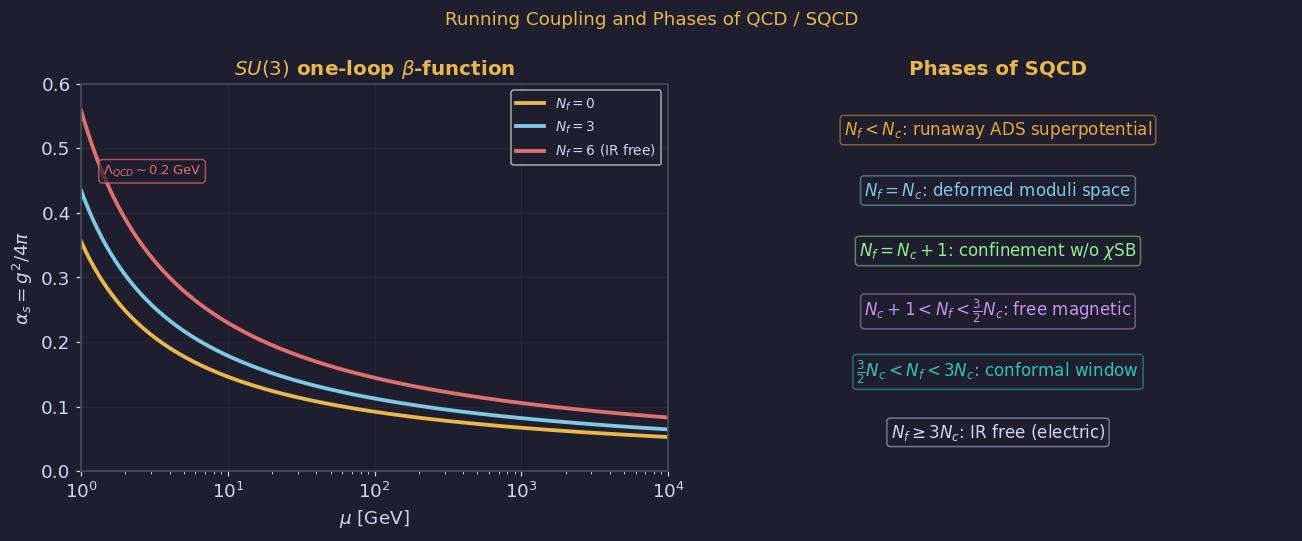

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Running Coupling and Phases of QCD / SQCD', color=GOLD, fontsize=12)
mu = np.logspace(0, 4, 400)   # 1 ~ 10000 GeV

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'$SU(3)$ one-loop $\beta$-function', color=GOLD)

# Lambda_QCD ~ 0.2 GeV → alpha_s(M_Z=91 GeV) ~ 0.118 as reference
# alpha_s(mu) = 2*pi / (b0 * ln(mu/Lambda))
Lambda_QCD = 0.2   # GeV

for Nf, col, lbl in [(0, GOLD, r'$N_f=0$'),
                     (3, BLUE, r'$N_f=3$'),
                     (6, RED,  r'$N_f=6$ (IR free)')]:
    b0 = 11.0 - 2.0*Nf/3.0
    if b0 <= 0:            # IR free: runs in reverse
        Lambda_eff = 1e5   # fake Landau pole far in UV
    else:
        Lambda_eff = Lambda_QCD
    log_arg = mu / Lambda_eff
    # avoid log(0) and unphysical region
    with np.errstate(invalid='ignore', divide='ignore'):
        alpha = np.where(log_arg > 1.01,
                         2*np.pi / (b0 * np.log(log_arg)),
                         np.nan)
    ax.plot(mu, alpha, color=col, lw=2.5, label=lbl)

ax.set_xlabel(r'$\mu$ [GeV]')
ax.set_ylabel(r'$\alpha_s = g^2/4\pi$')
ax.set_xscale('log')
ax.set_ylim(0, 0.6)
ax.set_xlim(1, 1e4)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)
ax.axhline(0, color=EDGE, lw=0.8)
# mark confinement scale
ax.axvline(Lambda_QCD*5, color=RED, lw=1, ls=':', alpha=0.5)
ax.text(1.4, 0.46, r'$\Lambda_{QCD}\sim 0.2$ GeV', fontsize=8.5, color=RED,
        bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.7))

ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('Phases of SQCD', color=GOLD)
phases = [
    (r'$N_f<N_c$: runaway ADS superpotential', ORAN),
    (r'$N_f=N_c$: deformed moduli space', BLUE),
    (r'$N_f=N_c+1$: confinement w/o $\chi$SB', GREEN),
    (r'$N_c+1<N_f<\frac{3}{2}N_c$: free magnetic', PURP),
    (r'$\frac{3}{2}N_c<N_f<3N_c$: conformal window', TEAL),
    (r'$N_f\geq 3N_c$: IR free (electric)', FG),
]
ys = np.linspace(0.88, 0.10, len(phases))
for (txt, col), y in zip(phases, ys):
    ax2.text(0.5, y, txt, ha='center', va='center', fontsize=11, color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.22', fc=BG, ec=col, alpha=0.5))
plt.tight_layout()
save('fig01_running_phases.png', fig)

saved->figures/ch05/fig02_anomalies.png


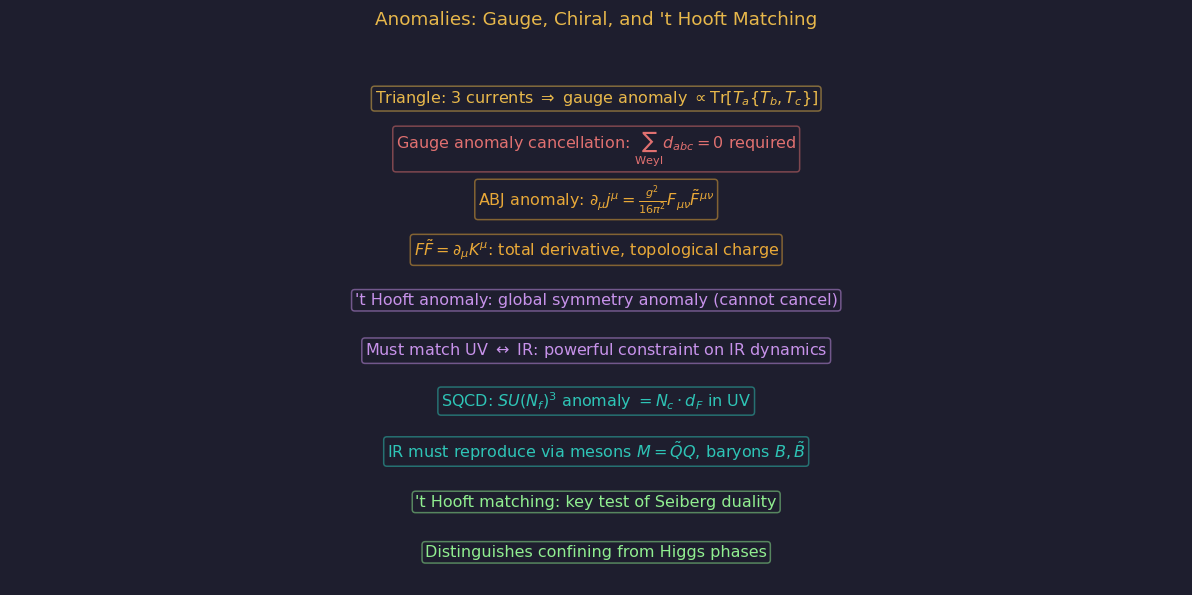

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
fig.suptitle("Anomalies: Gauge, Chiral, and 't Hooft Matching", color=GOLD, fontsize=12)
ax.set_facecolor(BG); ax.axis('off')
rows = [
    (r"Triangle: 3 currents $\Rightarrow$ gauge anomaly $\propto \mathrm{Tr}[T_a\{T_b,T_c\}]$", GOLD),
    (r"Gauge anomaly cancellation: $\sum_{\rm Weyl} d_{abc}=0$ required", RED),
    (r"ABJ anomaly: $\partial_\mu j^\mu = \frac{g^2}{16\pi^2} F_{\mu\nu}\tilde{F}^{\mu\nu}$", ORAN),
    (r"$F\tilde{F} = \partial_\mu K^\mu$: total derivative, topological charge", ORAN),
    (r"'t Hooft anomaly: global symmetry anomaly (cannot cancel)", PURP),
    (r"Must match UV $\leftrightarrow$ IR: powerful constraint on IR dynamics", PURP),
    (r"SQCD: $SU(N_f)^3$ anomaly $= N_c \cdot d_F$ in UV", TEAL),
    (r"IR must reproduce via mesons $M=\tilde{Q}Q$, baryons $B, \tilde{B}$", TEAL),
    (r"'t Hooft matching: key test of Seiberg duality", GREEN),
    (r"Distinguishes confining from Higgs phases", GREEN),
]
ys = np.linspace(0.92, 0.06, len(rows))
for (txt, col), y in zip(rows, ys):
    ax.text(0.5, y, txt, ha='center', va='center', fontsize=10.5, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.5))
plt.tight_layout()
save('fig02_anomalies.png', fig)

saved->figures/ch05/fig03_instantons_ads.png


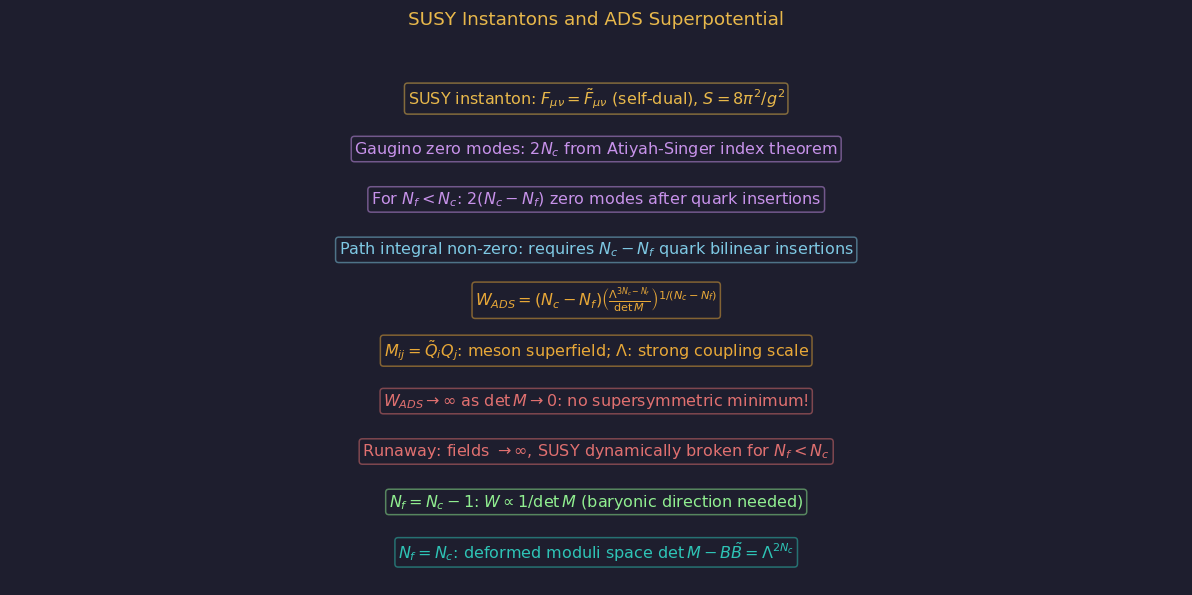

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))
fig.suptitle('SUSY Instantons and ADS Superpotential', color=GOLD, fontsize=12)
ax.set_facecolor(BG); ax.axis('off')
rows = [
    (r"SUSY instanton: $F_{\mu\nu}=\tilde{F}_{\mu\nu}$ (self-dual), $S=8\pi^2/g^2$", GOLD),
    (r"Gaugino zero modes: $2N_c$ from Atiyah-Singer index theorem", PURP),
    (r"For $N_f<N_c$: $2(N_c-N_f)$ zero modes after quark insertions", PURP),
    (r"Path integral non-zero: requires $N_c-N_f$ quark bilinear insertions", BLUE),
    (r"$W_{ADS}=(N_c-N_f)\left(\frac{\Lambda^{3N_c-N_f}}{\det M}\right)^{1/(N_c-N_f)}$", ORAN),
    (r"$M_{ij}=\tilde{Q}_i Q_j$: meson superfield; $\Lambda$: strong coupling scale", ORAN),
    (r"$W_{ADS}\to\infty$ as $\det M\to 0$: no supersymmetric minimum!", RED),
    (r"Runaway: fields $\to\infty$, SUSY dynamically broken for $N_f<N_c$", RED),
    (r"$N_f=N_c-1$: $W\propto 1/\det M$ (baryonic direction needed)", GREEN),
    (r"$N_f=N_c$: deformed moduli space $\det M - B\tilde{B}=\Lambda^{2N_c}$", TEAL),
]
ys = np.linspace(0.92, 0.06, len(rows))
for (txt, col), y in zip(rows, ys):
    ax.text(0.5, y, txt, ha='center', va='center', fontsize=10.5, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.5))
plt.tight_layout()
save('fig03_instantons_ads.png', fig)

In [5]:

import shutil
shutil.make_archive('susyft_ch05_figures','zip','figures/ch05')
try:
    from google.colab import files; files.download('susyft_ch05_figures.zip')
except ImportError:
    print('figures saved to figures/ch05/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>